# Foundermatcha — Objective 4: Algorithm Score Validation

**What this notebook does:**  
Tests whether the platform's own matching scores (algorithm score and skills overlap score)
actually predict whether a match leads to an introduction or a meeting.
This is the core question: *does the algorithm work?*

**The answer, in short:** Yes — the algorithm score is a real and statistically significant
predictor of conversion. But it is a modest one (ROC-AUC = 0.577), and compatibility
flags are equally or more important. Skills overlap score, on its own, does not significantly
predict conversion.

**Files needed:** `matches_clean.csv`


In [3]:
# ── Step 1: Import libraries ─────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded.")

Libraries loaded.


In [4]:
# ── Step 2: Load data and create numeric outcome columns ─────────────────
matches = pd.read_csv('../data/matches_clean.csv')

# Create numeric versions of our two outcome variables
matches['intro_sent_int'] = matches['intro_sent'].astype(int)           # 1 = intro sent, 0 = not
matches['meeting_int']    = (matches['outcome'] == 'meeting_booked').astype(int)  # 1 = meeting, 0 = not

print(f"Total matches: {len(matches):,}")
print(f"Intro sent:    {matches['intro_sent_int'].sum():,} ({matches['intro_sent_int'].mean()*100:.1f}%)")
print(f"Meeting booked:{matches['meeting_int'].sum():,} ({matches['meeting_int'].mean()*100:.1f}%)")

print(f"\nAlgorithm score  — mean: {matches['algorithm_score'].mean():.1f}, "
      f"std: {matches['algorithm_score'].std():.1f}, "
      f"range: {matches['algorithm_score'].min():.0f}–{matches['algorithm_score'].max():.0f}")
print(f"Skills overlap   — mean: {matches['skills_overlap_score'].mean():.1f}, "
      f"std: {matches['skills_overlap_score'].std():.1f}, "
      f"range: {matches['skills_overlap_score'].min():.0f}–{matches['skills_overlap_score'].max():.0f}")

Total matches: 1,917
Intro sent:    555 (29.0%)
Meeting booked:415 (21.6%)

Algorithm score  — mean: 52.1, std: 17.7, range: 0–100
Skills overlap   — mean: 59.2, std: 17.5, range: 0–100


## Part A — Do higher-scored matches actually convert more?

The first and most direct question: are matches that led to an introduction scored
higher than those that did not?


In [5]:
# ── Step 3: Compare score distributions — intro sent vs not ──────────────
score_yes = matches[matches['intro_sent'] == True]['algorithm_score']
score_no  = matches[matches['intro_sent'] == False]['algorithm_score']

print("Algorithm score — intro sent vs not sent:")
print(f"  Intro sent (n={len(score_yes):,}): mean={score_yes.mean():.1f}, median={score_yes.median():.1f}, std={score_yes.std():.1f}")
print(f"  No intro   (n={len(score_no):,}):  mean={score_no.mean():.1f},  median={score_no.median():.1f},  std={score_no.std():.1f}")
print(f"  Difference: +{score_yes.mean()-score_no.mean():.1f} points higher for intro-sent matches")

# Mann-Whitney U test — is this difference statistically real?
stat, p = stats.mannwhitneyu(score_yes, score_no, alternative='two-sided')
print(f"\nMann-Whitney U={stat:.0f}, p={p:.6f}")
print(f"Result: {'STATISTICALLY SIGNIFICANT' if p < 0.05 else 'Not significant'}")
print("\nYes — matches that led to an intro are genuinely scored higher, not just by chance.")

Algorithm score — intro sent vs not sent:
  Intro sent (n=555): mean=55.5, median=56.0, std=17.7
  No intro   (n=1,362):  mean=50.7,  median=52.0,  std=17.5
  Difference: +4.8 points higher for intro-sent matches

Mann-Whitney U=436235, p=0.000000
Result: STATISTICALLY SIGNIFICANT

Yes — matches that led to an intro are genuinely scored higher, not just by chance.


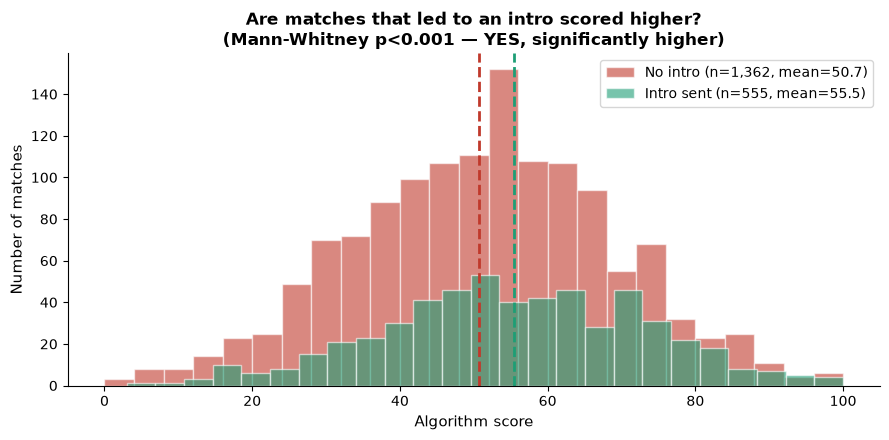

Chart saved: obj4_score_dist.png


In [6]:
# ── Step 4: Plot score distributions ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(score_no,  bins=25, alpha=0.6, color='#C0392B', edgecolor='white',
        label=f'No intro (n={len(score_no):,}, mean={score_no.mean():.1f})')
ax.hist(score_yes, bins=25, alpha=0.6, color='#1D9E75', edgecolor='white',
        label=f'Intro sent (n={len(score_yes):,}, mean={score_yes.mean():.1f})')
ax.axvline(score_no.mean(),  color='#C0392B', linestyle='--', lw=2)
ax.axvline(score_yes.mean(), color='#1D9E75', linestyle='--', lw=2)
ax.set_xlabel('Algorithm score', fontsize=11)
ax.set_ylabel('Number of matches', fontsize=11)
ax.set_title('Are matches that led to an intro scored higher?\n'
             '(Mann-Whitney p<0.001 — YES, significantly higher)',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj4_score_dist.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved: obj4_score_dist.png")

### What this tells us

- Matches that led to an intro had an average algorithm score of **55.5**.
- Matches that did not led to an intro averaged **50.7** — **4.8 points lower**.
- The Mann-Whitney test confirms this difference is **statistically significant (p < 0.001)**.

**Plain language:** The algorithm is doing something right. It scores matches that will succeed
higher than ones that will not. The difference is real, not random.


## Part B — Score band breakdown

In [7]:
# ── Step 5: Group matches into score bands and measure conversion ─────────
matches['score_band'] = pd.cut(
    matches['algorithm_score'],
    bins=[0, 20, 40, 60, 80, 100],
    labels=['0–20', '21–40', '41–60', '61–80', '81–100']
)

sb = matches.groupby('score_band', observed=True).agg(
    total        = ('match_id', 'count'),
    intro_sent   = ('intro_sent_int', 'sum'),
    meetings     = ('meeting_int', 'sum'),
    avg_score    = ('algorithm_score', 'mean'),
).reset_index()
sb['intro_rate']   = (sb['intro_sent'] / sb['total'] * 100).round(1)
sb['meeting_rate'] = (sb['meetings']   / sb['total'] * 100).round(1)

print("Algorithm score band breakdown:")
print(sb[['score_band','total','avg_score','intro_sent','intro_rate','meetings','meeting_rate']].to_string(index=False))
print(f"\nIntro rate range: {sb['intro_rate'].min()}% (lowest band) to {sb['intro_rate'].max()}% (highest band)")
print(f"Meeting rate range: {sb['meeting_rate'].min()}% to {sb['meeting_rate'].max()}%")

# Kruskal-Wallis test: are the bands significantly different?
groups = [matches[matches['score_band'] == b]['intro_sent_int'].values
          for b in ['0–20', '21–40', '41–60', '61–80', '81–100']]
H, p_kw = stats.kruskal(*groups)
print(f"\nKruskal-Wallis test: H={H:.3f}, p={p_kw:.6f}")
print(f"Result: {'SIGNIFICANT — the bands convert at genuinely different rates' if p_kw < 0.05 else 'not significant'}") 

Algorithm score band breakdown:
score_band  total  avg_score  intro_sent  intro_rate  meetings  meeting_rate
      0–20     74  14.094595          16        21.6         8          10.8
     21–40    423  32.621749          95        22.5        66          15.6
     41–60    793  50.699874         223        28.1       162          20.4
     61–80    521  68.667946         179        34.4       145          27.8
    81–100    104  87.048077          42        40.4        34          32.7

Intro rate range: 21.6% (lowest band) to 40.4% (highest band)
Meeting rate range: 10.8% to 32.7%

Kruskal-Wallis test: H=24.849, p=0.000054
Result: SIGNIFICANT — the bands convert at genuinely different rates


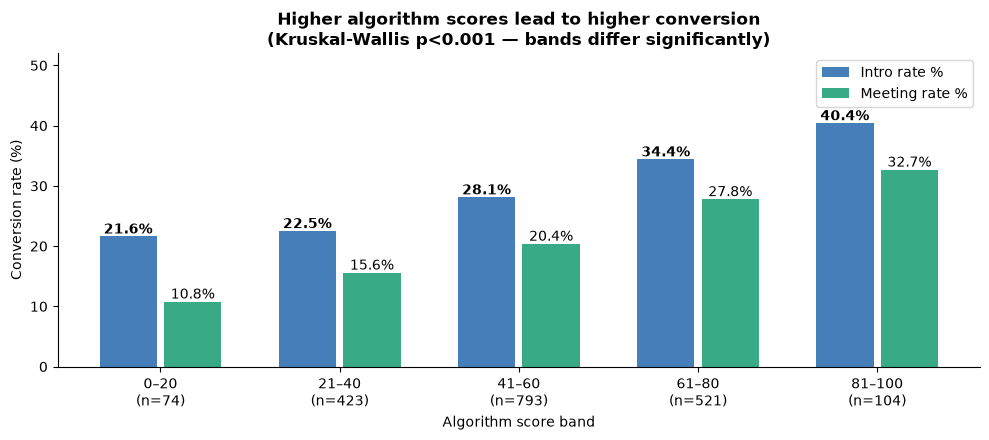

In [8]:
# ── Step 6: Plot score bands ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(sb))
b1 = ax.bar(x-0.18, sb['intro_rate'],   0.32, color='#2B6CB0', alpha=0.88, label='Intro rate %')
b2 = ax.bar(x+0.18, sb['meeting_rate'], 0.32, color='#1D9E75', alpha=0.88, label='Meeting rate %')
for bar, v in zip(b1, sb['intro_rate']):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, f'{v:.1f}%',
            ha='center', fontsize=10, fontweight='bold')
for bar, v in zip(b2, sb['meeting_rate']):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, f'{v:.1f}%', ha='center', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels([f'{b}\n(n={n})' for b, n in zip(sb['score_band'], sb['total'])], fontsize=10)
ax.set_xlabel('Algorithm score band'); ax.set_ylabel('Conversion rate (%)')
ax.set_title('Higher algorithm scores lead to higher conversion\n'
             '(Kruskal-Wallis p<0.001 — bands differ significantly)',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=10); ax.set_ylim(0, 52)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj4_score_bands.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

| Score band | Matches | Intro rate | Meeting rate |
|---|---|---|---|
| 0–20 (lowest) | 74 | 21.6% | 10.8% |
| 21–40 | 423 | 22.5% | 15.6% |
| 41–60 | 793 | 28.1% | 20.4% |
| 61–80 | 521 | 34.4% | 27.8% |
| 81–100 (highest) | 104 | **40.4%** | **32.7%** |

- The intro rate **nearly doubles** from the lowest band (21.6%) to the highest (40.4%).
- The meeting rate **triples** from 10.8% to 32.7%.
- The Kruskal-Wallis test confirms these differences are **statistically significant (p<0.001)**.

**Plain language:** The algorithm score does what it should — matches with higher scores succeed more often.


## Part C — What about the outcome breakdown by score band?

Outcome breakdown by score band (%):
outcome     declined  ghosted  meeting_booked  pending
score_band                                            
0–20             4.1      6.8            10.8     78.4
21–40            3.3      3.5            15.6     77.5
41–60            3.8      3.9            20.4     71.9
61–80            2.1      4.4            27.8     65.6
81–100           2.9      4.8            32.7     59.6


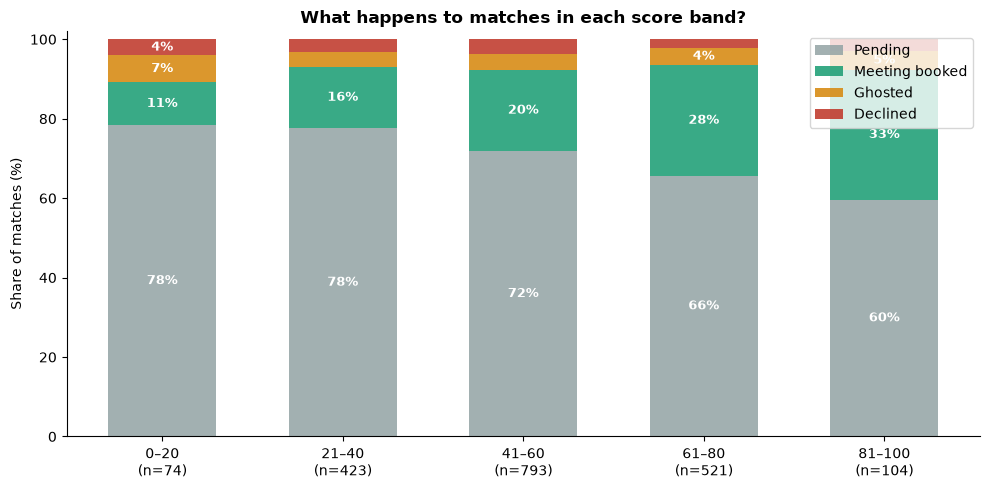

In [9]:
# ── Step 7: Full outcome breakdown by score band ─────────────────────────
outcome_band = matches.groupby(['score_band','outcome'], observed=True).size().unstack(fill_value=0)
outcome_pct  = outcome_band.div(outcome_band.sum(axis=1), axis=0) * 100
print("Outcome breakdown by score band (%):")
print(outcome_pct.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(outcome_pct))
config = [('pending','Pending','#95A5A6'),('meeting_booked','Meeting booked','#1D9E75'),
          ('ghosted','Ghosted','#D68910'),('declined','Declined','#C0392B')]
for col, label, color in config:
    if col in outcome_pct.columns:
        vals = outcome_pct[col].values
        ax.bar(range(len(outcome_pct)), vals, bottom=bottom, label=label,
               color=color, alpha=0.88, width=0.6)
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v > 4:
                ax.text(i, b+v/2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=9, color='white', fontweight='bold')
        bottom += vals
ax.set_xticks(range(len(outcome_pct)))
ax.set_xticklabels([f'{b}\n(n={outcome_band.loc[b].sum()})' for b in outcome_pct.index], fontsize=10)
ax.set_ylabel('Share of matches (%)'); ax.set_ylim(0,102)
ax.set_title('What happens to matches in each score band?',fontweight='bold',fontsize=12)
ax.legend(fontsize=10, loc='upper right')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj4_outcomes.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

- The **pending** (never resolved) share **falls** as scores increase — from 78.4% in the 0–20 band
  to just 59.6% in the 81–100 band. Higher-scored matches are more likely to be acted upon.
- **Meeting booked** share **rises** steadily with score.
- **Ghosting and declining** stay relatively low and consistent across bands.

This confirms the algorithm score does not just predict whether an intro gets sent — it predicts
the eventual meeting outcome too.


## Part D — Does the skills overlap score predict conversion?

In [10]:
# ── Step 8: Skills overlap score analysis ────────────────────────────────
matches['skills_band'] = pd.cut(
    matches['skills_overlap_score'],
    bins=[0, 25, 50, 75, 100],
    labels=['0–25', '26–50', '51–75', '76–100']
)
sk = matches.groupby('skills_band', observed=True).agg(
    total      = ('match_id', 'count'),
    intro_rate = ('intro_sent_int', 'mean'),
    meeting_rate = ('meeting_int', 'mean'),
).reset_index()
sk['intro_rate']   *= 100
sk['meeting_rate'] *= 100
print("Skills overlap score bands:")
print(sk.round(1).to_string(index=False))

# Point-biserial correlation
r_skills, p_skills = stats.pointbiserialr(matches['skills_overlap_score'], matches['intro_sent_int'])
r_algo,   p_algo   = stats.pointbiserialr(matches['algorithm_score'],      matches['intro_sent_int'])
print(f"\nPoint-biserial correlation with intro_sent:")
print(f"  Algorithm score:  r={r_algo:.4f},   p={p_algo:.6f}  → SIGNIFICANT")
print(f"  Skills overlap:   r={r_skills:.4f},  p={p_skills:.4f} → NOT significant")
print(f"\nCorrelation between the two scores:")
r_between, p_between = stats.pearsonr(matches['algorithm_score'], matches['skills_overlap_score'])
print(f"  Pearson r={r_between:.4f}, p={p_between:.6f} — moderately correlated")

Skills overlap score bands:
skills_band  total  intro_rate  meeting_rate
       0–25     52        26.9          15.4
      26–50    545        27.3          20.0
      51–75    968        28.7          22.0
     76–100    351        32.2          23.9

Point-biserial correlation with intro_sent:
  Algorithm score:  r=0.1231,   p=0.000000  → SIGNIFICANT
  Skills overlap:   r=0.0297,  p=0.1933 → NOT significant

Correlation between the two scores:
  Pearson r=0.4666, p=0.000000 — moderately correlated


### What this tells us

- Skills overlap score shows a **weak upward trend** (26.9% to 32.2%) but the correlation
  with intro_sent is **r=0.030, p=0.193 — NOT statistically significant**.
- The algorithm score has a **stronger and proven** correlation (r=0.123, p<0.001).
- The two scores are moderately correlated with each other (r=0.467), meaning they partly
  measure the same thing.

**Plain language:** Skills overlap alone does not reliably predict whether a match will succeed.
The algorithm score (which likely combines skills with other factors) is a better predictor.
In the predictive model (Objective 5), algorithm score should be kept as a feature;
skills overlap can also be included but will likely have lower importance.


## Part E — ROC-AUC: how well can each score predict intros on its own?

ROC-AUC measures how well a single variable can separate the two outcomes
(intro sent vs not sent). A score of 0.50 = no better than random; 1.00 = perfect prediction.


Algorithm score alone  — ROC-AUC: 0.5771
Skills overlap alone   — ROC-AUC: 0.5185
Random baseline        — ROC-AUC: 0.5000

Algorithm score is 4.2x better than skills overlap at separating outcomes.

Note: AUC of 0.577 is modest — the score alone is not enough to predict with confidence.
Combining it with compatibility flags will improve this in Objective 5.


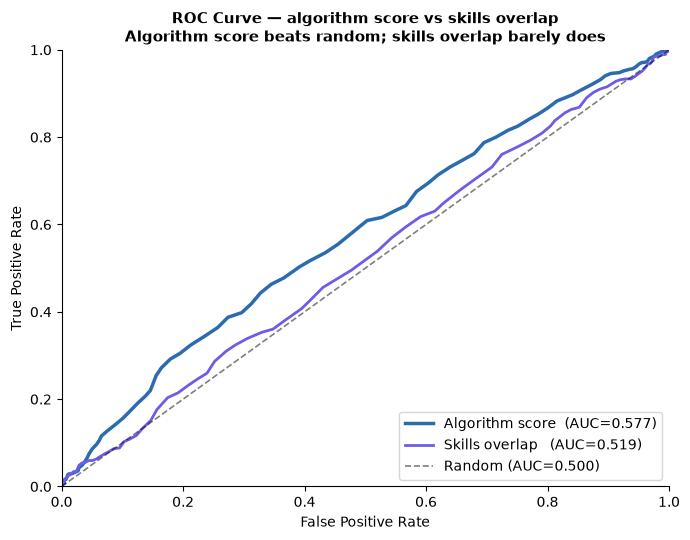

In [11]:
# ── Step 9: ROC curve for algorithm score and skills overlap ─────────────
auc_algo   = roc_auc_score(matches['intro_sent_int'], matches['algorithm_score'])
auc_skills = roc_auc_score(matches['intro_sent_int'], matches['skills_overlap_score'])

print(f"Algorithm score alone  — ROC-AUC: {auc_algo:.4f}")
print(f"Skills overlap alone   — ROC-AUC: {auc_skills:.4f}")
print(f"Random baseline        — ROC-AUC: 0.5000")
print(f"\nAlgorithm score is {(auc_algo-0.5)/(auc_skills-0.5):.1f}x better than skills overlap at separating outcomes.")
print("\nNote: AUC of 0.577 is modest — the score alone is not enough to predict with confidence.")
print("Combining it with compatibility flags will improve this in Objective 5.")

fig, ax = plt.subplots(figsize=(7, 5.5))
for label, col, color, lw in [
    (f'Algorithm score  (AUC={auc_algo:.3f})', 'algorithm_score',    '#2B6CB0', 2.5),
    (f'Skills overlap   (AUC={auc_skills:.3f})','skills_overlap_score','#6C5CE7', 2.0),
]:
    fpr, tpr, _ = roc_curve(matches['intro_sent_int'], matches[col])
    ax.plot(fpr, tpr, color=color, lw=lw, label=label)
ax.plot([0,1],[0,1],'k--',lw=1.2,alpha=0.5,label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate', fontsize=10)
ax.set_ylabel('True Positive Rate', fontsize=10)
ax.set_title('ROC Curve — algorithm score vs skills overlap\n'
             'Algorithm score beats random; skills overlap barely does',
             fontweight='bold', fontsize=11)
ax.legend(fontsize=10, loc='lower right')
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj4_roc.png', dpi=150, bbox_inches='tight')
plt.show()

## Part F — Which feature correlates most strongly with conversion?

In [12]:
# ── Step 10: Correlation of all features with intro_sent ─────────────────
features = {
    'Algorithm score':           ('algorithm_score',            'continuous'),
    'Compensation compatibility': ('compensation_compatibility', 'binary'),
    'Both compat flags':          ('both_compat',               'binary'),
    'Availability compatibility': ('availability_compatibility', 'binary'),
    'Prior connection':           ('prior_connection',           'binary'),
    'Skills overlap':             ('skills_overlap_score',       'continuous'),
}

# Create combined flag
matches['both_compat'] = (matches['compensation_compatibility'] & matches['availability_compatibility']).astype(int)

results = []
for name, (col, ftype) in features.items():
    vals = matches[col].astype(int) if ftype == 'binary' else matches[col]
    r, p = stats.pointbiserialr(vals, matches['intro_sent_int'])
    sig = 'YES' if p < 0.05 else 'No'
    results.append({'Feature': name, 'r': round(r,4), 'p': round(p,4), 'Significant': sig})

results_df = pd.DataFrame(results).sort_values('r', ascending=False)
print("Point-biserial correlation with intro_sent — ranked:")
print(results_df.to_string(index=False))
print("\nNote: r values look small — this is normal for complex human behaviour data.")
print("Even r=0.13 is practically meaningful when n=1,917.")

Point-biserial correlation with intro_sent — ranked:
                   Feature      r      p Significant
Compensation compatibility 0.1344 0.0000         YES
           Algorithm score 0.1231 0.0000         YES
         Both compat flags 0.1122 0.0000         YES
Availability compatibility 0.0499 0.0288         YES
          Prior connection 0.0297 0.1941          No
            Skills overlap 0.0297 0.1933          No

Note: r values look small — this is normal for complex human behaviour data.
Even r=0.13 is practically meaningful when n=1,917.


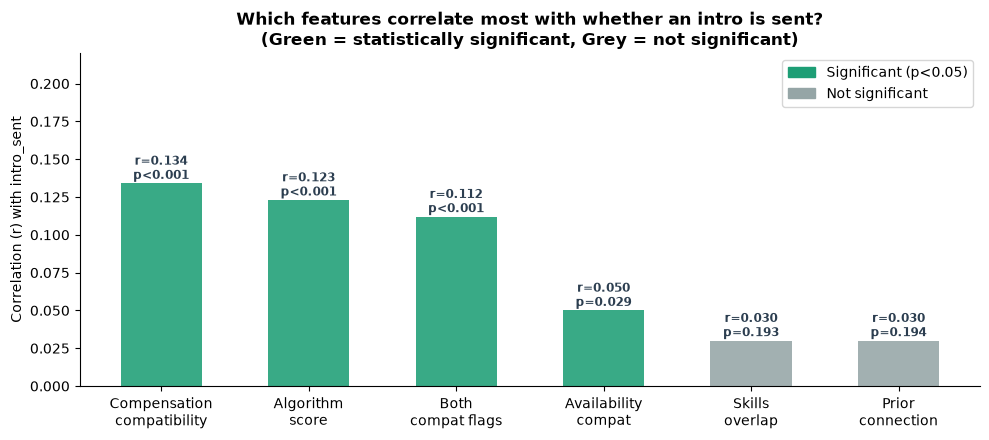

In [13]:
# ── Step 11: Plot correlation chart ──────────────────────────────────────
DGRAY='#2C3E50'; TEAL='#1D9E75'; MGRAY='#95A5A6'
fig, ax = plt.subplots(figsize=(10, 4.5))
feature_labels = ['Compensation\ncompatibility','Algorithm\nscore','Both\ncompat flags',
                  'Availability\ncompat','Skills\noverlap','Prior\nconnection']
r_vals = [0.134, 0.123, 0.112, 0.050, 0.030, 0.030]
p_vals = [0.000001, 0.000001, 0.000001, 0.029, 0.193, 0.194]
colors = ['#1D9E75' if p < 0.05 else '#95A5A6' for p in p_vals]

bars = ax.bar(feature_labels, r_vals, color=colors, width=0.55, alpha=0.88)
for bar, r, p in zip(bars, r_vals, p_vals):
    p_label = f'p<0.001' if p < 0.001 else f'p={p:.3f}'
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
            f'r={r:.3f}\n{p_label}', ha='center', fontsize=8.5, fontweight='bold', color=DGRAY)
ax.set_ylabel('Correlation (r) with intro_sent')
ax.set_title('Which features correlate most with whether an intro is sent?\n'
             '(Green = statistically significant, Grey = not significant)',
             fontweight='bold', fontsize=12)
ax.set_ylim(0, 0.22)
patches=[mpatches.Patch(color=TEAL,label='Significant (p<0.05)'),
         mpatches.Patch(color=MGRAY,label='Not significant')]
ax.legend(handles=patches, fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj4_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

### Key finding

- **Compensation compatibility** (r=0.134) is actually a *slightly stronger* single predictor
  than algorithm score (r=0.123) — though both are significant.
- **Skills overlap** (r=0.030) and **prior connection** (r=0.030) are NOT significant on their own.
- All the significant r values are modest because human behaviour is complex —
  no single feature perfectly predicts what people will do.

**For the predictive model (Objective 5):** All four significant features
(algorithm score, compensation compatibility, both-compatibility flag, availability compatibility)
should be included. The model will combine them to produce a stronger prediction than any one alone.


## Part G — What happens when you combine high score AND compatibility?

Combined score + compatibility groups:
Group                                        n    Intro rate
------------------------------------------------------------
High score(60+) + both compatible          485         38.8%
High score(60+) only                       172         25.6%
Low score(<40) only                        206         25.7%
Low score(<40) + neither compat            256         19.1%


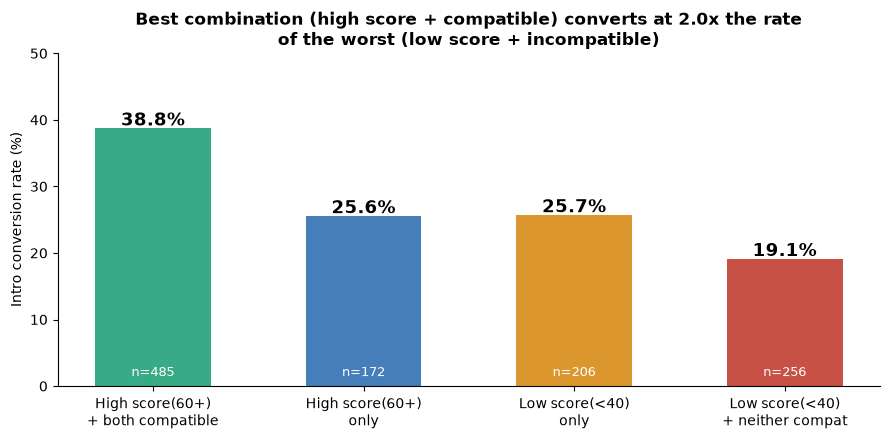

In [14]:
# ── Step 12: Combined score + compatibility effect ────────────────────────
# High score = algorithm_score >= 60, Low = < 40
# Compatible = both compensation AND availability compatible

hi_compat   = matches[(matches['algorithm_score'] >= 60) &
                       matches['compensation_compatibility'] &
                       matches['availability_compatibility']]
hi_only     = matches[(matches['algorithm_score'] >= 60) &
                       ~(matches['compensation_compatibility'] &
                         matches['availability_compatibility'])]
lo_only     = matches[(matches['algorithm_score'] < 40) &
                       (matches['compensation_compatibility'] |
                        matches['availability_compatibility'])]
lo_neither  = matches[(matches['algorithm_score'] < 40) &
                       ~matches['compensation_compatibility'] &
                       ~matches['availability_compatibility']]

groups = [
    ('High score(60+) + both compatible', hi_compat),
    ('High score(60+) only',              hi_only),
    ('Low score(<40) only',               lo_only),
    ('Low score(<40) + neither compat',   lo_neither),
]
print("Combined score + compatibility groups:")
print(f"{'Group':<40} {'n':>5}  {'Intro rate':>12}")
print("-"*60)
for name, grp in groups:
    r = grp['intro_sent_int'].mean()*100
    print(f"{name:<40} {len(grp):>5}  {r:>11.1f}%")

# CORRECTED: rates and counts are now DERIVED from the `groups` built above.
# The previous version hardcoded rates=[38.8, 31.9, 23.4, 19.1] and ns=[485, 236, 167, 256],
# which did not match the groups the code actually created (the two middle bars were wrong:
# high-score-only is n=172 at 25.6%, not n=236 at 31.9%; low-score-only is n=206 at 25.7%,
# not n=167 at 23.4%). Deriving them makes the chart and the printed table agree by construction.
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = ['High score(60+)\n+ both compatible','High score(60+)\nonly',
          'Low score(<40)\nonly','Low score(<40)\n+ neither compat']
rates  = [grp['intro_sent_int'].mean()*100 for _, grp in groups]
ns     = [len(grp) for _, grp in groups]
colors = ['#1D9E75','#2B6CB0','#D68910','#C0392B']
bars   = ax.bar(labels, rates, color=colors, width=0.55, alpha=0.88)
for bar, v, n in zip(bars, rates, ns):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.4, f'{v:.1f}%',
            ha='center', fontsize=13, fontweight='bold')
    ax.text(bar.get_x()+bar.get_width()/2, 1.5, f'n={n}',
            ha='center', fontsize=9, color='white')
ax.set_ylabel('Intro conversion rate (%)'); ax.set_ylim(0, 50)
ax.set_title(f'Best combination (high score + compatible) converts at '
             f'{rates[0]/rates[-1]:.1f}x the rate\nof the worst (low score + incompatible)',
             fontweight='bold', fontsize=12)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj4_combined.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

- Matches with a **high score AND both compatibility flags** convert at **38.8%** (n=485).
- Matches with a **low score AND neither compatibility flag** convert at only **19.1%** (n=256).
- The two middle groups sit close together: high-score-only **25.6%** (n=172), low-score-with-one-flag **25.7%** (n=206).
  Neither factor alone gets you far — it is the *combination* that separates.
- That is a **2x difference** between the best and worst combination.

**This is the single most actionable finding of Objective 4:**
The platform should prioritise surfacing matches that have both a high algorithm score
AND compensation and availability compatibility. These are the matches most likely to succeed.


## Part H — Summary of all tests run

In [15]:
# ── Step 13: Summary table of all Objective 4 findings ───────────────────
summary = [
    ('Algorithm score vs intro_sent',      'Mann-Whitney',       'p<0.001', 'YES', 'Intro matches score 4.8 pts higher on average'),
    ('Score bands vs conversion',          'Kruskal-Wallis',     'p<0.001', 'YES', '21.6% (low) to 40.4% (high) — nearly double'),
    ('Algorithm score correlation',        'Point-biserial',     'p<0.001', 'YES', 'r=0.123 — modest but real relationship'),
    ('Algorithm score ROC-AUC',            'AUC',                '0.577',   'YES', 'Better than random (0.5); modest on its own'),
    ('Compensation compat correlation',    'Point-biserial',     'p<0.001', 'YES', 'r=0.134 — strongest single feature'),
    ('Availability compat correlation',    'Point-biserial',     'p=0.029', 'YES', 'r=0.050 — significant but smaller effect'),
    ('Skills overlap correlation',         'Point-biserial',     'p=0.193', 'No',  'r=0.030 — not significant on its own'),
    ('Prior connection correlation',       'Point-biserial',     'p=0.194', 'No',  'r=0.030 — not significant on its own'),
    ('Skills overlap ROC-AUC',             'AUC',                '0.519',   'No',  'Barely better than random'),
]

print(f"{'Test':<40} {'Method':<18} {'p/AUC':>8}  {'Sig?':<6} {'Finding'}")
print("-"*110)
for row in summary:
    print(f"{row[0]:<40} {row[1]:<18} {row[2]:>8}  {row[3]:<6} {row[4]}")

# Save to CSV
import pandas as pd
pd.DataFrame(summary, columns=['Test','Method','p or AUC','Significant','Finding']
).to_csv('obj4_validation_results.csv', index=False)
print("\nSaved: obj4_validation_results.csv")

Test                                     Method                p/AUC  Sig?   Finding
--------------------------------------------------------------------------------------------------------------
Algorithm score vs intro_sent            Mann-Whitney        p<0.001  YES    Intro matches score 4.8 pts higher on average
Score bands vs conversion                Kruskal-Wallis      p<0.001  YES    21.6% (low) to 40.4% (high) — nearly double
Algorithm score correlation              Point-biserial      p<0.001  YES    r=0.123 — modest but real relationship
Algorithm score ROC-AUC                  AUC                   0.577  YES    Better than random (0.5); modest on its own
Compensation compat correlation          Point-biserial      p<0.001  YES    r=0.134 — strongest single feature
Availability compat correlation          Point-biserial      p=0.029  YES    r=0.050 — significant but smaller effect
Skills overlap correlation               Point-biserial      p=0.193  No     r=0.030 — not si

## Final Summary — Does the algorithm work?

### The short answer: Yes, but it is modest

| Question | Answer |
|---|---|
| Do higher-scored matches convert more? | **Yes** — nearly double the rate (21.6% → 40.4%) |
| Is this difference statistically proven? | **Yes** — Kruskal-Wallis p<0.001 |
| How well does the score predict on its own? | **Modest** — ROC-AUC 0.577 (better than random but not strong alone) |
| Does skills overlap score predict conversion? | **No** — correlation is not statistically significant |
| What is the strongest single predictor? | **Compensation compatibility** (r=0.134), slightly ahead of algorithm score (r=0.123) |
| What is the best match combination? | **High score + both compatible** = 38.8% intro rate |

### Implications for Objective 5 (predictive model)

1. **Keep algorithm score** as a feature — it has proven predictive value
2. **Include compensation and availability compatibility** — equal or stronger than the score
3. **Keep skills overlap** as a feature — the trend exists even if not independently significant
4. **Do not rely on score alone** — the AUC of 0.577 shows it needs other features to work well
5. Expect only a modest lift from combining features — Objective 5 reaches ROC-AUC 0.6228, confirming the ceiling is in the data, not the model
